# 🌧️ MOD-04 — Descarga, Procesamiento y Pivoteo de Precipitación y Radiación Solar

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martin Naranjo Escobar

---

## 📋 Descripción del módulo

Este módulo descarga y transforma **dos variables climáticas** complementarias a la temperatura:

### Parte A — Precipitación (datos.gov.co · IDEAM)
- Descarga paginada desde el recurso `s54a-sgyg` de datos.gov.co
- Misma estructura de procesamiento que MOD-03: calendario → QC → agregación → pivoteo wide

### Parte B — Radiación Solar (NASA POWER API)
- Descarga mensual desde la API pública `power.larc.nasa.gov`
- Una petición por municipio usando sus coordenadas (lat/lon) del catálogo IDEAM
- Variables: `ALLSKY_SFC_SW_DWN` (radiación en superficie, MJ/m²/día)
- Resolución temporal: mensual → se asigna directamente a `mes_periodo`

La radiación solar es una variable crítica del proyecto porque **la nubosidad persistente reduce la fotosíntesis y puede disminuir el rendimiento arrocero hasta un 10-15%** según la literatura agroclimatológica.

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD04_precipitacion_radiacion.ipynb  ← Este archivo
├── data/
│   ├── raw/
│   │   ├── 04a_raw_Precipitacion.parquet    ← Descarga IDEAM sin modificar
│   │   └── 04b_raw_Radiacion_NASA.parquet   ← Descarga NASA POWER sin modificar
│   └── processed/
│       ├── 14_DF_Cobertura_Territorial.xlsx ← Entrada desde MOD-02
│       ├── 13_DF_Estaciones_Climaticas.xlsx ← Entrada desde MOD-02 (coordenadas)
│       ├── 19_DF_Precipitacion_Long.xlsx    ← Serie larga con calendario
│       ├── 20_DF_Precipitacion_Agr.xlsx     ← Agregación primaria (día)
│       ├── 21_DF_Precipitacion_Agr_SD.xlsx  ← Agregación secundaria (mes semestral)
│       ├── 22_DF_Precipitacion_Wide.xlsx    ← Formato wide listo para MOD-05
│       ├── 23_DF_Radiacion_Long.xlsx        ← Serie mensual NASA POWER
│       └── 24_DF_Radiacion_Wide.xlsx        ← Formato wide listo para MOD-05
└── backup/
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Descripción |
|------|-------------|
| **Entrada 1** | `data/processed/14_DF_Cobertura_Territorial.xlsx` — hoja `Filtros_MOD04_MOD05_MOD06` |
| **Entrada 2** | `data/processed/13_DF_Estaciones_Climaticas.xlsx` — coordenadas lat/lon por municipio |
| **Salida 1** | `data/raw/04a_raw_Precipitacion.parquet` — descarga IDEAM sin modificar |
| **Salida 2** | `data/raw/04b_raw_Radiacion_NASA.parquet` — descarga NASA POWER sin modificar |
| **Salida 3-5** | `data/processed/19..22_DF_Precipitacion_*.xlsx` — flujo completo precipitación |
| **Salida 6-7** | `data/processed/23..24_DF_Radiacion_*.xlsx` — flujo radiación solar |

---

## 🔗 Dependencias entre módulos

```
MOD-01 → MOD-02
  └─→ 14_DF_Cobertura_Territorial.xlsx  (hoja Filtros_MOD04_MOD05_MOD06)
  └─→ 13_DF_Estaciones_Climaticas.xlsx  (coordenadas lat/lon)
        └─→ [MOD-04]  Precipitación + Radiación
              ├─→ 22_DF_Precipitacion_Wide.xlsx  ─→ MOD-05
              └─→ 24_DF_Radiacion_Wide.xlsx      ─→ MOD-05
```

---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

In [ ]:
# ============================================================
# MOD-04 | Precipitación (IDEAM) + Radiación Solar (NASA POWER)
# ============================================================
!pip install openpyxl pyarrow fastparquet -q

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os
import time
import warnings

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount('/content/drive')

print("✅ Entorno configurado correctamente")

Mounted at /content/drive
✅ Entorno configurado correctamente


---
## 📁 CELDA 2 — Definición de rutas y parámetros del proyecto

> **Instrucción:** Verifica que `RUTA_BASE` coincida con la carpeta en tu Google Drive.

In [ ]:
# ============================================================
# CONFIGURACIÓN DE RUTAS Y PARÁMETROS — Módulo MOD-04
# ============================================================

# ⚠️ Ajusta esta ruta si tu carpeta en Drive tiene otro nombre
RUTA_BASE      = "/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II"

# Subcarpetas
RUTA_RAW       = os.path.join(RUTA_BASE, "data", "raw")
RUTA_PROCESSED = os.path.join(RUTA_BASE, "data", "processed")
RUTA_BACKUP    = os.path.join(RUTA_BASE, "backup")

for ruta in [RUTA_RAW, RUTA_PROCESSED, RUTA_BACKUP]:
    os.makedirs(ruta, exist_ok=True)

# ── Archivos de ENTRADA (generados por MOD-02) ──────────────
ENTRADA_COBERTURA  = os.path.join(RUTA_PROCESSED, "14_DF_Cobertura_Territorial.xlsx")
ENTRADA_ESTACIONES = os.path.join(RUTA_PROCESSED, "13_DF_Estaciones_Climaticas.xlsx")

# ── Archivos de SALIDA — Parte A: Precipitación ─────────────
ARCHIVO_PREC_RAW    = os.path.join(RUTA_RAW,       "04a_raw_Precipitacion.parquet")
ARCHIVO_PREC_LONG_PARQUET = os.path.join(RUTA_PROCESSED,  "19_DF_Precipitacion_Long.parquet")  # Parquet: soporta >1M filas
ARCHIVO_PREC_LONG         = os.path.join(RUTA_PROCESSED,  "19_DF_Precipitacion_Long.xlsx")     # Excel: muestra inspeccion (50K)
ARCHIVO_PREC_AGR_PARQUET  = os.path.join(RUTA_PROCESSED,  "20_DF_Precipitacion_Agr.parquet")   # Parquet: puede superar 1M filas
ARCHIVO_PREC_AGR          = os.path.join(RUTA_PROCESSED,  "20_DF_Precipitacion_Agr.xlsx")      # Excel: muestra inspeccion (50K)
ARCHIVO_PREC_AGR_SD = os.path.join(RUTA_PROCESSED,  "21_DF_Precipitacion_Agr_SD.xlsx")
ARCHIVO_PREC_WIDE   = os.path.join(RUTA_PROCESSED,  "22_DF_Precipitacion_Wide.xlsx")

# ── Archivos de SALIDA — Parte B: Radiación Solar ───────────
ARCHIVO_RAD_RAW     = os.path.join(RUTA_RAW,       "04b_raw_Radiacion_NASA.parquet")
ARCHIVO_RAD_LONG    = os.path.join(RUTA_PROCESSED,  "23_DF_Radiacion_Long.xlsx")
ARCHIVO_RAD_WIDE    = os.path.join(RUTA_PROCESSED,  "24_DF_Radiacion_Wide.xlsx")

# ── Parámetros de descarga — Precipitación IDEAM ────────────
URL_PRECIPITACION   = "https://www.datos.gov.co/resource/s54a-sgyg.json"
FECHA_INI           = "2020-01-01"
FECHA_FIN           = "2024-12-31"
LIMIT_PAGINA        = 10000
MAX_PAGINAS         = 500
TIMEOUT_API         = 300

# ── Parámetros de descarga — Radiación NASA POWER ───────────
URL_NASA_POWER      = "https://power.larc.nasa.gov/api/temporal/monthly/point"
ANIO_INI_NASA       = 2020
ANIO_FIN_NASA       = 2024
# Variables NASA POWER a descargar (community=AG para uso agrícola)
NASA_PARAMS         = "ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN"
# ALLSKY_SFC_SW_DWN : Radiación solar total en superficie (cielo real) MJ/m²/día
# CLRSKY_SFC_SW_DWN : Radiación bajo cielo despejado (referencia) MJ/m²/día
TIMEOUT_NASA        = 120
NASA_FILL_VALUE     = -999.0   # Valor de datos faltantes en NASA POWER

# ── Parámetros de control de calidad — Precipitación ────────
PREC_MIN_VALIDA     =  0.0    # mm — no puede ser negativa
PREC_MAX_VALIDA     = 300.0   # mm — límite diario plausible en Colombia

print("📂 Rutas configuradas")
print(f"   Raw       → {RUTA_RAW}")
print(f"   Processed → {RUTA_PROCESSED}")
print(f"\n📅 Rango temporal: {FECHA_INI}  →  {FECHA_FIN}")
print()
for etiq, ruta in [("14_DF_Cobertura_Territorial.xlsx", ENTRADA_COBERTURA),
                   ("13_DF_Estaciones_Climaticas.xlsx",  ENTRADA_ESTACIONES)]:
    estado = '✅' if os.path.exists(ruta) else '❌ NO ENCONTRADO'
    print(f"   📥 {estado}  {etiq}")
print()
print("📤 Salidas de Parte A — Precipitación:")
for f in ["04a_raw_Precipitacion.parquet","19_DF_Precipitacion_Long.parquet",
          "20_DF_Precipitacion_Agr.parquet","21_DF_Precipitacion_Agr_SD.xlsx",
          "22_DF_Precipitacion_Wide.xlsx"]:
    print(f"   📄 {f}")
print("📤 Salidas de Parte B — Radiación Solar:")
for f in ["04b_raw_Radiacion_NASA.parquet","23_DF_Radiacion_Long.xlsx",
          "24_DF_Radiacion_Wide.xlsx"]:
    print(f"   📄 {f}")

📂 Rutas configuradas
   Raw       → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw
   Processed → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed

📅 Rango temporal: 2020-01-01  →  2024-12-31

   📥 ✅  14_DF_Cobertura_Territorial.xlsx
   📥 ✅  13_DF_Estaciones_Climaticas.xlsx

📤 Salidas de Parte A — Precipitación:
   📄 04a_raw_Precipitacion.parquet
   📄 19_DF_Precipitacion_Long.parquet
   📄 20_DF_Precipitacion_Agr.parquet
   📄 21_DF_Precipitacion_Agr_SD.xlsx
   📄 22_DF_Precipitacion_Wide.xlsx
📤 Salidas de Parte B — Radiación Solar:
   📄 04b_raw_Radiacion_NASA.parquet
   📄 23_DF_Radiacion_Long.xlsx
   📄 24_DF_Radiacion_Wide.xlsx


---
## 🔧 CELDA 3 — Funciones utilitarias compartidas (Partes A y B)

In [ ]:
# ============================================================
# FUNCIONES UTILITARIAS COMPARTIDAS — Módulo MOD-04
# ============================================================
import gc
import psutil

# ── Monitor de RAM ────────────────────────────────────────────
def ram_mb():
    proc = psutil.Process(os.getpid())
    return proc.memory_info().rss / 1_048_576

def reportar_ram(etapa=''):
    mb = ram_mb()
    emoji = '🟢' if mb < 3000 else ('🟡' if mb < 5000 else '🔴')
    label = f' [{etapa}]' if etapa else ''
    print(f'  {emoji} RAM usada{label}: {mb:,.0f} MB')

def limpiar_ram(*objetos, etapa=''):
    import ctypes
    for obj in objetos:
        del obj
    gc.collect()
    try:
        ctypes.CDLL('libc.so.6').malloc_trim(0)
    except Exception:
        pass
    reportar_ram(etapa)


# ── Normalizacion de texto ────────────────────────────────────
def normalizar_texto(serie):
    return serie.astype(str).str.strip().str.upper()


def crear_clave_territorial(df, col_depto, col_mun):
    return normalizar_texto(df[col_depto]) + '|' + normalizar_texto(df[col_mun])


# ── Variables de calendario (identica a MOD-03) ───────────────
def agregar_calendario(df, col_fecha='fechaobservacion'):
    df[col_fecha]     = pd.to_datetime(df[col_fecha], errors='coerce')
    df['Anio']        = df[col_fecha].dt.year
    df['Mes']         = df[col_fecha].dt.month
    df['Dia']         = df[col_fecha].dt.day
    df['Hora']        = df[col_fecha].dt.hour
    df['Semestre']    = df['Mes'].map(lambda x: 'A' if 1<=x<=6 else ('B' if 7<=x<=12 else None))
    df['Periodo']     = df['Anio'].astype('Int64').astype(str) + df['Semestre'].astype(str)
    df['mes_periodo'] = ((df['Mes'] - 1) % 6) + 1
    df['Jornada']     = df['Hora'].map(lambda h: 'D' if 6<=h<=17 else 'N')
    return df


# ── WHERE clause para API SoQL ────────────────────────────────
def _safe_literal(s):
    return str(s).upper().replace("'", "''") if s else ''


def build_where(depto, mpio, fecha_ini, fecha_fin):
    d, m = _safe_literal(depto), _safe_literal(mpio)
    return (
        f"(upper(departamento)='{d}' AND upper(municipio)='{m}') "
        f"AND fechaobservacion between '{fecha_ini}T00:00:00' and '{fecha_fin}T23:59:59'"
    )


# ── DESCARGA + PROCESAMIENTO EN STREAMING POR MUNICIPIO ───────
def descargar_procesar_municipio(url, depto, mpio, fecha_ini, fecha_fin,
                                  val_min, val_max,
                                  limit=10000, max_pages=500,
                                  timeout=300, pausa=0.3):
    """
    Descarga pagina a pagina para UN municipio y procesa cada pagina
    inmediatamente antes de pasar a la siguiente.
    Pasos por pagina:
      1. Conversion de tipos numericos
      2. Normalizacion de texto territorial
      3. Filtro de rango fisico (descarta outliers antes de acumular)
      4. Variables de calendario
      5. Downcasting float64->float32, int->Int16 (menor huella RAM)
      6. Elimina el raw del chunk tras procesarlo
    Nunca acumula el raw completo en memoria.
    Retorna (df_procesado, n_raw_descargados) o (None, 0) si sin datos.
    """
    where  = build_where(depto, mpio, fecha_ini, fecha_fin)
    offset = 0
    chunks = []
    n_raw  = 0

    for page in range(1, max_pages + 1):
        params = {'$where': where, '$limit': limit, '$offset': offset}
        try:
            r = requests.get(url, params=params, timeout=timeout)
            r.raise_for_status()
            data = r.json()
        except Exception as e:
            print(f'      Error p{page}: {e}. Reintentando...')
            time.sleep(5)
            r = requests.get(url, params=params, timeout=timeout)
            r.raise_for_status()
            data = r.json()

        n_pag = len(data)
        if n_pag == 0:
            break
        n_raw += n_pag

        # ── Construir chunk y liberar JSON raw de inmediato ───
        chunk = pd.DataFrame(data)
        del data, r
        gc.collect()

        # Tipos numericos
        chunk['valorobservado'] = pd.to_numeric(chunk['valorobservado'], errors='coerce')
        for col in ['latitud', 'longitud', 'altitud']:
            if col in chunk.columns:
                chunk[col] = pd.to_numeric(chunk[col], errors='coerce')

        # Normalizar texto territorial
        for col in ['departamento', 'municipio']:
            if col in chunk.columns:
                chunk[col] = normalizar_texto(chunk[col])

        # Filtro de rango fisico (elimina outliers groseros antes de acumular)
        chunk = chunk.dropna(subset=['valorobservado'])
        chunk = chunk[chunk['valorobservado'].between(val_min, val_max)].copy()

        # Variables de calendario
        chunk = agregar_calendario(chunk, col_fecha='fechaobservacion')
        chunk = chunk.dropna(subset=['fechaobservacion']).copy()

        # Trazabilidad
        chunk['depto_filtro'] = depto
        chunk['mpio_filtro']  = mpio

        # Downcasting: reduce ~50% la huella de RAM vs float64/int64
        for c in chunk.select_dtypes('float64').columns:
            chunk[c] = chunk[c].astype('float32')
        for c in ['Anio', 'Mes', 'Dia', 'Hora', 'mes_periodo']:
            if c in chunk.columns:
                chunk[c] = chunk[c].astype('Int16')

        chunks.append(chunk)
        del chunk
        gc.collect()

        print(f'      Pag {page:3d} | offset={offset:7,} | brutos={n_pag:,} | acumulados={n_raw:,}')
        offset += limit
        if n_pag < limit:
            break
        time.sleep(pausa)

    if not chunks:
        return None, n_raw

    df_mun = pd.concat(chunks, ignore_index=True)
    del chunks
    gc.collect()
    return df_mun, n_raw


# ── Bandera outlier IQR (aplicada post-concat) ────────────────
def flag_iqr(df, col='valorobservado'):
    """Agrega columna outlier_iqr por (departamento, municipio)."""
    def _flag(grupo):
        q1, q3 = grupo[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        return ~grupo[col].between(q1 - 1.5*iqr, q3 + 1.5*iqr)
    df['outlier_iqr'] = (
        df.groupby(['departamento', 'municipio'], group_keys=False)
          .apply(_flag)
    )
    return df


# ── Pivoteo wide generico ─────────────────────────────────────
def pivotar_wide(df_agr_sd, cols_valores, prefijo_cols=None):
    df_wide = df_agr_sd.pivot_table(
        index   = ['Periodo', 'departamento', 'municipio'],
        columns = 'mes_periodo',
        values  = cols_valores,
        aggfunc = 'first'
    )
    df_wide.columns = [f'{var}_m{mes}' for var, mes in df_wide.columns]
    df_wide = df_wide.reset_index()
    cols_id   = ['Periodo', 'departamento', 'municipio']
    cols_feat = sorted([c for c in df_wide.columns if c not in cols_id])
    return df_wide[cols_id + cols_feat]


# ── Reporte rapido ────────────────────────────────────────────
def reporte_df(df, nombre=''):
    etiq = f' -- {nombre}' if nombre else ''
    print(f"\n{'='*58}")
    print(f'  DataFrame{etiq}')
    print(f"{'='*58}")
    print(f'  Filas    : {df.shape[0]:,}')
    print(f'  Columnas : {df.shape[1]}')
    nulos   = df.isna().sum()
    nulos_c = nulos[nulos > 0]
    if nulos_c.empty:
        print('  Nulos    : Sin valores nulos')
    else:
        print(f'  Nulos    : {len(nulos_c)} cols con nulos')
        for c, n in nulos_c.items():
            print(f'             - {c}: {n:,} ({n/len(df)*100:.1f}%)')
    print(f"{'='*58}\n")


# ── Guardar Excel ─────────────────────────────────────────────
def guardar_excel(df_o_dict, ruta, nombre_log=''):
    etiqueta = nombre_log or os.path.basename(ruta)
    if isinstance(df_o_dict, dict):
        with pd.ExcelWriter(ruta, engine='openpyxl') as w:
            for hoja, df in df_o_dict.items():
                df.to_excel(w, sheet_name=hoja, index=False)
        total = sum(d.shape[0] for d in df_o_dict.values())
        print(f'OK {etiqueta} -> {ruta}')
        print(f'   Hojas : {list(df_o_dict.keys())} | Total filas: {total:,}\n')
    else:
        df_o_dict.to_excel(ruta, index=False, engine='openpyxl')
        print(f'OK {etiqueta} -> {ruta}')
        print(f'   Shape : {df_o_dict.shape[0]:,} x {df_o_dict.shape[1]}\n')


print('Funciones utilitarias + gestion RAM cargadas')
reportar_ram('inicio')


Funciones utilitarias + gestion RAM cargadas
  🟢 RAM usada [inicio]: 183 MB


---
## 📥 CELDA 4 — Cargar lista de filtros territoriales desde MOD-02

In [ ]:
# ============================================================
# CARGAR FILTROS TERRITORIALES Y CATÁLOGO DE ESTACIONES
# Entrada desde MOD-02
# ============================================================

for archivo, nombre in [(ENTRADA_COBERTURA,  "14_DF_Cobertura_Territorial.xlsx"),
                        (ENTRADA_ESTACIONES,  "13_DF_Estaciones_Climaticas.xlsx")]:
    if not os.path.exists(archivo):
        raise FileNotFoundError(
            f"❌ Archivo no encontrado: {archivo}\n"
            "   Ejecuta primero MOD02_estaciones_climaticas.ipynb"
        )

# ── Lista de filtros territoriales ──────────────────────────
df_filtros = pd.read_excel(
    ENTRADA_COBERTURA,
    sheet_name="Filtros_MOD04_MOD05_MOD06",
    engine="openpyxl"
)
df_filtros["Departamento"] = normalizar_texto(df_filtros["Departamento"])
df_filtros["Municipio"]    = normalizar_texto(df_filtros["Municipio"])

filtros = list(
    df_filtros[["Departamento","Municipio"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

# ── Catálogo de estaciones (para obtener coordenadas lat/lon) ─
df_estaciones = pd.read_excel(ENTRADA_ESTACIONES, engine="openpyxl")
for col in ["departamento", "municipio"]:
    if col in df_estaciones.columns:
        df_estaciones[col] = normalizar_texto(df_estaciones[col])

# Tabla de coordenadas representativas por municipio
# (mediana de lat/lon de todas las estaciones del municipio)
df_coordenadas = (
    df_estaciones
    .dropna(subset=["latitud", "longitud"])
    .groupby(["departamento", "municipio"], as_index=False)
    .agg(
        lat = ("latitud",  "median"),
        lon = ("longitud", "median"),
    )
)
df_coordenadas["key"] = crear_clave_territorial(
    df_coordenadas, "departamento", "municipio"
)

print(f"✅ Filtros territoriales cargados: {len(filtros)} pares (depto, municipio)")
print(f"   Coordenadas disponibles       : {len(df_coordenadas)} municipios con lat/lon")
print()
for i, (d, m) in enumerate(filtros, 1):
    key = f"{d}|{m}"
    match = df_coordenadas[df_coordenadas["key"]==key]
    coords = f"lat={match['lat'].values[0]:.3f}, lon={match['lon'].values[0]:.3f}" \
             if len(match) > 0 else "⚠️ sin coordenadas"
    print(f"  {i:2d}. {d:20s} — {m:25s}  [{coords}]")

✅ Filtros territoriales cargados: 131 pares (depto, municipio)
   Coordenadas disponibles       : 1028 municipios con lat/lon

   1. ANTIOQUIA            — PUERTO BERRÍO              [lat=6.496, lon=-74.410]
   2. ARAUCA               — FORTUL                     [⚠️ sin coordenadas]
   3. ATLÁNTICO            — PONEDERA                   [⚠️ sin coordenadas]
   4. ATLÁNTICO            — REPELÓN                    [⚠️ sin coordenadas]
   5. ATLÁNTICO            — SUAN                       [⚠️ sin coordenadas]
   6. BOLÍVAR              — ACHÍ                       [⚠️ sin coordenadas]
   7. BOLÍVAR              — ARENAL                     [⚠️ sin coordenadas]
   8. BOLÍVAR              — CLEMENCIA                  [⚠️ sin coordenadas]
   9. BOLÍVAR              — CÓRDOBA                    [⚠️ sin coordenadas]
  10. BOLÍVAR              — MAHATES                    [⚠️ sin coordenadas]
  11. BOLÍVAR              — MARÍA LA BAJA              [⚠️ sin coordenadas]
  12. BOLÍVAR         

---
# 🌧️ PARTE A — PRECIPITACIÓN (datos.gov.co · IDEAM)

---
## 🌐 CELDA 5 — Descarga paginada de precipitación desde datos.gov.co

> **Nota:** Esta celda puede tardar varios minutos. No interrumpir durante la ejecución.

In [ ]:
# ============================================================
# CELDA 5 [v2.0] — Precipitación IDEAM (recurso s54a-sgyg)
#
# LÓGICA CONDICIONAL:
#   SI  04a_raw_Precipitacion.parquet ya existe en data/raw/
#       → Carga directamente el archivo (evita re-descarga)
#   SI NO existe
#       → Ejecuta la descarga paginada completa en streaming
#
# Esto permite continuar el pipeline cuando la sesión de Colab
# se quedó sin recursos tras completar la descarga.
# ============================================================
import pyarrow as pa
import pyarrow.parquet as pq

if os.path.exists(ARCHIVO_PREC_RAW):
    # ── RAMA A: archivo ya existe — cargar directamente ──────
    size_mb = os.path.getsize(ARCHIVO_PREC_RAW) / 1_048_576
    print(f'Archivo encontrado: {ARCHIVO_PREC_RAW}')
    print(f'Tamano: {size_mb:.2f} MB')
    print('Cargando df_precipitacion desde disco (sin re-descarga)...')
    reportar_ram('antes de carga')

    df_precipitacion = pd.read_parquet(ARCHIVO_PREC_RAW, engine='pyarrow')

    # Normalizar tipos por si el parquet viene de otra sesion
    if 'fechaobservacion' in df_precipitacion.columns:
        df_precipitacion['fechaobservacion'] = pd.to_datetime(
            df_precipitacion['fechaobservacion'], errors='coerce'
        )
    if 'valorobservado' in df_precipitacion.columns:
        df_precipitacion['valorobservado'] = pd.to_numeric(
            df_precipitacion['valorobservado'], errors='coerce'
        )
    for col in ['departamento', 'municipio']:
        if col in df_precipitacion.columns:
            df_precipitacion[col] = (
                df_precipitacion[col].astype(str).str.strip().str.upper()
            )

    # Recalcular variables de calendario si faltan
    if 'Periodo' not in df_precipitacion.columns:
        print('Recalculando variables de calendario...')
        df_precipitacion = agregar_calendario(
            df_precipitacion, col_fecha='fechaobservacion'
        )

    # Recalcular clave territorial si falta
    if 'key' not in df_precipitacion.columns:
        df_precipitacion['key'] = crear_clave_territorial(
            df_precipitacion, 'departamento', 'municipio'
        )

    # Recalcular bandera outlier IQR si falta
    if 'outlier_iqr' not in df_precipitacion.columns:
        print('Recalculando flag outlier IQR...')
        df_precipitacion = flag_iqr(df_precipitacion, col='valorobservado')

    reportar_ram('post-carga')
    print(f'\nOK df_precipitacion cargado desde archivo existente')
    print(f'   Shape      : {df_precipitacion.shape[0]:,} filas x {df_precipitacion.shape[1]} columnas')
    print(f'   Municipios : {df_precipitacion["municipio"].nunique() if "municipio" in df_precipitacion.columns else "N/A"}')
    if 'fechaobservacion' in df_precipitacion.columns:
        print(f'   Rango fechas: {df_precipitacion["fechaobservacion"].min()} -> {df_precipitacion["fechaobservacion"].max()}')
    display(df_precipitacion.head(4))

else:
    # ── RAMA B: archivo NO existe — descarga paginada ────────
    print(f'Archivo NO encontrado: {ARCHIVO_PREC_RAW}')
    print('Iniciando descarga streaming de precipitacion...')
    print(f'   Fuente    : {URL_PRECIPITACION}')
    print(f'   Rango     : {FECHA_INI}  ->  {FECHA_FIN}')
    print(f'   Municipios: {len(filtros)}')
    print('=' * 58)
    reportar_ram('antes de descarga')

    sin_registros  = []
    n_raw_total    = 0
    n_proc_total   = 0
    pq_writer      = None
    dfs_procesados = []

    SCHEMA_PARQUET_RAW = pa.schema([
        pa.field('codigoestacion',    pa.string()),
        pa.field('codigosensor',      pa.string()),
        pa.field('fechaobservacion',  pa.timestamp('ns')),
        pa.field('valorobservado',    pa.float32()),
        pa.field('nombreestacion',    pa.string()),
        pa.field('departamento',      pa.string()),
        pa.field('municipio',         pa.string()),
        pa.field('zonahidrografica',  pa.string()),
        pa.field('latitud',           pa.float32()),
        pa.field('longitud',          pa.float32()),
        pa.field('descripcionsensor', pa.string()),
        pa.field('unidadmedida',      pa.string()),
        pa.field('Anio',              pa.int16()),
        pa.field('Mes',               pa.int16()),
        pa.field('Dia',               pa.int16()),
        pa.field('Hora',              pa.int16()),
        pa.field('Semestre',          pa.string()),
        pa.field('Periodo',           pa.string()),
        pa.field('mes_periodo',       pa.int16()),
        pa.field('Jornada',           pa.string()),
        pa.field('depto_filtro',      pa.string()),
        pa.field('mpio_filtro',       pa.string()),
    ])
    print(f'Schema RAW fijo: {len(SCHEMA_PARQUET_RAW)} campos')
    t_inicio = time.time()

    for idx_mun, (depto, mpio) in enumerate(filtros, start=1):
        print(f'\n[{idx_mun}/{len(filtros)}] {depto} -- {mpio}')
        reportar_ram(f'inicio {mpio}')

        df_mun, n_raw_mun = descargar_procesar_municipio(
            url       = URL_PRECIPITACION,
            depto     = depto,
            mpio      = mpio,
            fecha_ini = FECHA_INI,
            fecha_fin = FECHA_FIN,
            val_min   = PREC_MIN_VALIDA,
            val_max   = PREC_MAX_VALIDA,
            limit     = LIMIT_PAGINA,
            max_pages = MAX_PAGINAS,
            timeout   = TIMEOUT_API,
        )
        n_raw_total += n_raw_mun

        if df_mun is None or df_mun.empty:
            print(f'    Sin registros validos')
            sin_registros.append((depto, mpio))
            continue

        n_proc_total += len(df_mun)
        print(f'    Brutos: {n_raw_mun:,} | Procesados: {len(df_mun):,}')

        cols_schema = [f.name for f in SCHEMA_PARQUET_RAW]
        for col in cols_schema:
            if col not in df_mun.columns:
                df_mun[col] = None
        tabla_raw = pa.Table.from_pandas(
            df_mun[cols_schema],
            schema=SCHEMA_PARQUET_RAW,
            preserve_index=False
        )
        if pq_writer is None:
            pq_writer = pq.ParquetWriter(
                ARCHIVO_PREC_RAW, SCHEMA_PARQUET_RAW, compression='snappy'
            )
        pq_writer.write_table(tabla_raw)
        del tabla_raw
        gc.collect()

        dfs_procesados.append(df_mun)
        del df_mun
        gc.collect()
        reportar_ram(f'fin {mpio}')

    if pq_writer is not None:
        pq_writer.close()
        size_raw = os.path.getsize(ARCHIVO_PREC_RAW) / 1_048_576
        print(f'\nParquet RAW guardado: {ARCHIVO_PREC_RAW}')
        print(f'   Tamano: {size_raw:.2f} MB')
    else:
        print('Sin datos para guardar en RAW')

    if dfs_procesados:
        df_precipitacion = pd.concat(dfs_procesados, ignore_index=True)
        del dfs_procesados
        gc.collect()
    else:
        df_precipitacion = pd.DataFrame()

    if not df_precipitacion.empty:
        print('Calculando banderas outlier IQR...')
        df_precipitacion = flag_iqr(df_precipitacion, col='valorobservado')
        df_precipitacion['key'] = crear_clave_territorial(
            df_precipitacion, 'departamento', 'municipio'
        )

    t_total = time.time() - t_inicio
    print(f'\n' + '=' * 58)
    print(f'  Descarga completada en {t_total/60:.1f} min')
    print(f'  Registros brutos    : {n_raw_total:,}')
    print(f'  Registros procesados: {n_proc_total:,}')
    print(f'  Municipios con datos: {len(filtros)-len(sin_registros)}/{len(filtros)}')
    if sin_registros:
        print(f'  Sin registros: {sin_registros}')
    print('=' * 58)
    reportar_ram('post-descarga')

# ── Reporte final independiente de la rama ejecutada ─────────
if not df_precipitacion.empty:
    reporte_df(df_precipitacion, 'df_precipitacion -- Serie procesada')
    cols_v = [c for c in ['fechaobservacion','Anio','Mes','Dia','Semestre',
                          'Periodo','mes_periodo','Jornada']
              if c in df_precipitacion.columns]
    display(df_precipitacion[cols_v].head(6))
    print('\nRegistros por municipio:')
    display(
        df_precipitacion.groupby(['departamento','municipio'])
                        .size().reset_index(name='n_registros')
                        .sort_values('n_registros', ascending=False)
    )
else:
    print('AVISO: df_precipitacion esta vacio.')


Archivo encontrado: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw/04a_raw_Precipitacion.parquet
Tamano: 77.01 MB
Cargando df_precipitacion desde disco (sin re-descarga)...
  🟢 RAM usada [antes de carga]: 217 MB
Recalculando flag outlier IQR...
  🔴 RAM usada [post-carga]: 5,410 MB

OK df_precipitacion cargado desde archivo existente
   Shape      : 9,618,437 filas x 24 columnas
   Municipios : 64
   Rango fechas: 2020-01-01 00:00:00 -> 2024-12-31 23:58:00


,codigoestacion,codigosensor,fechaobservacion,valorobservado,nombreestacion,departamento,municipio,zonahidrografica,latitud,longitud,...,Dia,Hora,Semestre,Periodo,mes_periodo,Jornada,depto_filtro,mpio_filtro,key,outlier_iqr
0,0023097030,0240,2020-01-01 17:10:00,0.0,PTO BERRIO TX GPRS,ANTIOQUIA,PUERTO BERRÍO,MEDIO MAGDALENA,6.485,-74.401001,...,1,17,A,2020A,1,D,ANTIOQUIA,PUERTO BERRÍO,ANTIOQUIA|PUERTO BERRÍO,False
1,0023097030,0240,2020-01-01 17:50:00,0.0,PTO BERRIO TX GPRS,ANTIOQUIA,PUERTO BERRÍO,MEDIO MAGDALENA,6.485,-74.401001,...,1,17,A,2020A,1,D,ANTIOQUIA,PUERTO BERRÍO,ANTIOQUIA|PUERTO BERRÍO,False
2,0023097030,0240,2020-01-01 18:40:00,0.0,PTO BERRIO TX GPRS,ANTIOQUIA,PUERTO BERRÍO,MEDIO MAGDALENA,6.485,-74.401001,...,1,18,A,2020A,1,N,ANTIOQUIA,PUERTO BERRÍO,ANTIOQUIA|PUERTO BERRÍO,False
3,0023097030,0240,2020-01-01 20:10:00,0.0,PTO BERRIO TX GPRS,ANTIOQUIA,PUERTO BERRÍO,MEDIO MAGDALENA,6.485,-74.401001,...,1,20,A,2020A,1,N,ANTIOQUIA,PUERTO BERRÍO,ANTIOQUIA|PUERTO BERRÍO,False



  DataFrame -- df_precipitacion -- Serie procesada
  Filas    : 9,618,437
  Columnas : 24
  Nulos    : Sin valores nulos



,fechaobservacion,Anio,Mes,Dia,Semestre,Periodo,mes_periodo,Jornada
0,2020-01-01 17:10:00,2020,1,1,A,2020A,1,D
1,2020-01-01 17:50:00,2020,1,1,A,2020A,1,D
2,2020-01-01 18:40:00,2020,1,1,A,2020A,1,N
3,2020-01-01 20:10:00,2020,1,1,A,2020A,1,N
4,2020-01-01 22:20:00,2020,1,1,A,2020A,1,N
5,2020-01-01 16:30:00,2020,1,1,A,2020A,1,D



Registros por municipio:


,departamento,municipio,n_registros
16,CESAR,VALLEDUPAR,955302
53,TOLIMA,IBAGUÉ,634087
8,CASANARE,YOPAL,489375
19,CÓRDOBA,MONTERÍA,481574
49,TOLIMA,ATACO,446274
...,...,...,...
48,TOLIMA,ARMERO,17290
31,HUILA,TERUEL,16062
33,HUILA,YAGUARÁ,10728
57,TOLIMA,PRADO,2303


---
## 🧹 CELDA 7 — Limpieza de tipos, calendario y control de calidad

In [ ]:
# ============================================================
# VERIFICACION Y COBERTURA TERRITORIAL
# La limpieza, tipos, calendario, rango fisico y outlier_iqr
# ya fueron aplicados en streaming durante la descarga.
# Esta celda verifica cobertura y libera variables intermedias.
# ============================================================

if df_precipitacion.empty:
    raise RuntimeError('df_precipitacion esta vacio. Revisa la celda de descarga.')

# ── Cobertura territorial ──────────────────────────────────────
keys_desc = set(df_precipitacion['key'].dropna())
df_filtros['key'] = crear_clave_territorial(df_filtros, 'Departamento', 'Municipio')
df_filtros['en_precipitacion'] = df_filtros['key'].isin(keys_desc)

n_total    = len(df_filtros)
n_ok       = df_filtros['en_precipitacion'].sum()
n_falt     = n_total - n_ok

print('=' * 55)
print('  COBERTURA TERRITORIAL -- Precipitacion')
print('=' * 55)
print(f'  Municipios solicitados : {n_total}')
print(f'  Con datos descargados  : {n_ok}  ({n_ok/n_total*100:.1f}%)')
print(f'  Sin datos (API vacia)  : {n_falt}  ({n_falt/n_total*100:.1f}%)')
print('=' * 55)

if n_falt > 0:
    faltantes = df_filtros[~df_filtros['en_precipitacion']][['Departamento','Municipio']]
    print('\nMunicipios sin datos de precipitacion:')
    display(faltantes.reset_index(drop=True))
    print('   Seran imputados en MOD-06 con mediana departamental.')

# ── Estadisticas rapidas ──────────────────────────────────────
print('\nEstadisticas de valorobservado (post-QC):')
display(df_precipitacion['valorobservado'].describe().round(3).to_frame())

n_outlier = df_precipitacion['outlier_iqr'].sum() if 'outlier_iqr' in df_precipitacion.columns else 0
print(f'\nOutliers IQR marcados (no eliminados): {n_outlier:,} ({n_outlier/len(df_precipitacion)*100:.2f}%)')
reportar_ram('post-limpieza')


  COBERTURA TERRITORIAL -- Precipitacion
  Municipios solicitados : 131
  Con datos descargados  : 64  (48.9%)
  Sin datos (API vacia)  : 67  (51.1%)

Municipios sin datos de precipitacion:


,Departamento,Municipio
0,ARAUCA,FORTUL
1,ATLÁNTICO,PONEDERA
2,ATLÁNTICO,REPELÓN
3,BOLÍVAR,ACHÍ
4,BOLÍVAR,ARENAL
...,...,...
62,TOLIMA,FALAN
63,TOLIMA,FLANDES
64,TOLIMA,ORTEGA
65,TOLIMA,SAN LUIS


   Seran imputados en MOD-06 con mediana departamental.

Estadisticas de valorobservado (post-QC):


,valorobservado
count,9618437.000
mean,0.037
std,0.572
min,0.000
25%,0.000
50%,0.000
75%,0.000
max,30.000



Outliers IQR marcados (no eliminados): 369,295 (3.84%)
  🔴 RAM usada [post-limpieza]: 5,436 MB


---
## 💾 CELDA 8 — Guardar serie larga de precipitación en `data/processed/`

In [ ]:
# ============================================================
# GUARDAR SERIE LARGA PRECIPITACIÓN
# ⚠️  Con Top-50 municipios puede superar 1M filas.
#    → Formato principal : Parquet (sin límite de filas)
#    → Formato inspección: Excel con primeras 50,000 filas
# ============================================================

n_filas_long = df_precipitacion.shape[0]
print(f"📊 Serie larga: {n_filas_long:,} filas × {df_precipitacion.shape[1]} columnas")

# ── Guardado principal en Parquet ────────────────────────
df_precipitacion.to_parquet(ARCHIVO_PREC_LONG_PARQUET, index=False)
size_mb = os.path.getsize(ARCHIVO_PREC_LONG_PARQUET) / 1_048_576
print(f"✅ 19_DF_Precipitacion_Long.parquet → {ARCHIVO_PREC_LONG_PARQUET}")
print(f"   Shape  : {n_filas_long:,} × {df_precipitacion.shape[1]}")
print(f"   Tamaño : {size_mb:.2f} MB")

# ── Muestra Excel (primeras 50K filas para inspección) ───
LIMITE_EXCEL = 50_000
df_precipitacion.head(LIMITE_EXCEL).to_excel(ARCHIVO_PREC_LONG, index=False, engine="openpyxl")
print(f"✅ 19_DF_Precipitacion_Long.xlsx  → muestra {min(LIMITE_EXCEL, n_filas_long):,} filas (de {n_filas_long:,})")
print(f"   ⚠️  Para análisis completo usa el .parquet")

# ── Liberar serie larga tras guardar ─────────────────────
# Descomentaar si la RAM sigue alta:
# limpiar_ram(etapa='post-guardar Long')
reportar_ram('post-guardar Long')


📊 Serie larga: 9,618,437 filas × 24 columnas
✅ 19_DF_Precipitacion_Long.parquet → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/19_DF_Precipitacion_Long.parquet
   Shape  : 9,618,437 × 24
   Tamaño : 68.88 MB
✅ 19_DF_Precipitacion_Long.xlsx  → muestra 50,000 filas (de 9,618,437)
   ⚠️  Para análisis completo usa el .parquet
  🔴 RAM usada [post-guardar Long]: 5,958 MB


---
## 📐 CELDA 9 — Agregación primaria y secundaria de precipitación

In [ ]:
# ============================================================
# AGREGACIÓN PRIMARIA — Métricas diarias
# Nivel: Periodo × Depto × Municipio × mes_periodo × Día
# ============================================================

COLS_PREC = ["precipitacion_media","precipitacion_minima",
             "precipitacion_maxima","precipitacion_std","precipitacion_total"]

print("🔢 Agregación primaria (métricas diarias)...")

df_precipitacion_agr = (
    df_precipitacion
    .groupby(["Periodo","departamento","municipio","mes_periodo","Dia"], as_index=False)
    .agg(
        precipitacion_media  = ("valorobservado", "mean"),
        precipitacion_minima = ("valorobservado", "min"),
        precipitacion_maxima = ("valorobservado", "max"),
        precipitacion_std    = ("valorobservado", "std"),
        precipitacion_total  = ("valorobservado", "sum"),   # acumulado diario
        n_lecturas           = ("valorobservado", "count"),
    )
)
df_precipitacion_agr[COLS_PREC] = df_precipitacion_agr[COLS_PREC].round(3)

reporte_df(df_precipitacion_agr, "Agregación primaria diaria")

# ============================================================
# AGREGACIÓN SECUNDARIA — Métricas por mes del semestre
# Nivel: Periodo × Depto × Municipio × mes_periodo
# ============================================================

print("🔢 Agregación secundaria (por mes del semestre)...")

df_precipitacion_agr_sd = (
    df_precipitacion_agr
    .groupby(["Periodo","departamento","municipio","mes_periodo"], as_index=False)
    .agg(
        precipitacion_media  = ("precipitacion_media",  "mean"),
        precipitacion_minima = ("precipitacion_minima", "min"),
        precipitacion_maxima = ("precipitacion_maxima", "max"),
        precipitacion_std    = ("precipitacion_std",    "mean"),
        precipitacion_total  = ("precipitacion_total",  "sum"),  # acumulado mensual
        n_dias               = ("n_lecturas",           "count"),
    )
)
df_precipitacion_agr_sd[COLS_PREC] = df_precipitacion_agr_sd[COLS_PREC].round(3)

reporte_df(df_precipitacion_agr_sd, "Agregación secundaria por mes semestral")
display(df_precipitacion_agr_sd.head(8))

print("📊 Distribución de mes_periodo:")
print(df_precipitacion_agr_sd["mes_periodo"].value_counts().sort_index().to_string())

🔢 Agregación primaria (métricas diarias)...

  DataFrame -- Agregación primaria diaria
  Filas    : 45,314
  Columnas : 11
  Nulos    : 1 cols con nulos
             - precipitacion_std: 68 (0.2%)

🔢 Agregación secundaria (por mes del semestre)...

  DataFrame -- Agregación secundaria por mes semestral
  Filas    : 1,845
  Columnas : 10
  Nulos    : 1 cols con nulos
             - precipitacion_std: 3 (0.2%)



,Periodo,departamento,municipio,mes_periodo,precipitacion_media,precipitacion_minima,precipitacion_maxima,precipitacion_std,precipitacion_total,n_dias
0,2020A,ANTIOQUIA,PUERTO BERRÍO,1,0.000,0.0,0.0,0.000,0.0,31
1,2020A,ANTIOQUIA,PUERTO BERRÍO,2,0.000,0.0,0.0,0.000,0.0,29
2,2020A,ANTIOQUIA,PUERTO BERRÍO,3,0.000,0.0,0.0,0.000,0.0,31
3,2020A,ANTIOQUIA,PUERTO BERRÍO,4,0.000,0.0,0.0,0.000,0.0,30
4,2020A,ANTIOQUIA,PUERTO BERRÍO,5,0.000,0.0,0.0,0.000,0.0,31
5,2020A,ANTIOQUIA,PUERTO BERRÍO,6,0.000,0.0,0.0,0.000,0.0,30
6,2020A,ATLÁNTICO,SUAN,1,0.000,0.0,0.1,0.001,0.4,31
7,2020A,ATLÁNTICO,SUAN,2,0.002,0.0,4.1,0.014,7.8,29


📊 Distribución de mes_periodo:
mes_periodo
1    308
2    309
3    313
4    313
5    302
6    300


---
## 💾 CELDA 10 — Guardar agregaciones de precipitación en `data/processed/`

In [ ]:
# ============================================================
# GUARDAR AGREGACIONES PRECIPITACIÓN
# ⚠️  La agregación diaria puede superar 1M filas con Top-50.
#    → Agr. primaria  (diaria): Parquet + muestra Excel
#    → Agr. secundaria (mes):   Excel directo (siempre <50K)
# ============================================================

# ── Agregación primaria (nivel día) ─────────────────────
n_filas_agr = df_precipitacion_agr.shape[0]
print(f"📊 Agr. diaria: {n_filas_agr:,} filas × {df_precipitacion_agr.shape[1]} columnas")

df_precipitacion_agr.to_parquet(ARCHIVO_PREC_AGR_PARQUET, index=False)
size_agr = os.path.getsize(ARCHIVO_PREC_AGR_PARQUET) / 1_048_576
print(f"✅ 20_DF_Precipitacion_Agr.parquet → {ARCHIVO_PREC_AGR_PARQUET}")
print(f"   Shape  : {n_filas_agr:,} × {df_precipitacion_agr.shape[1]}")
print(f"   Tamaño : {size_agr:.2f} MB")

LIMITE_EXCEL_AGR = 50_000
if n_filas_agr <= 1_048_576:
    df_precipitacion_agr.to_excel(ARCHIVO_PREC_AGR, index=False, engine="openpyxl")
    print(f"✅ 20_DF_Precipitacion_Agr.xlsx  → {n_filas_agr:,} filas (completo)")
else:
    df_precipitacion_agr.head(LIMITE_EXCEL_AGR).to_excel(ARCHIVO_PREC_AGR, index=False, engine="openpyxl")
    print(f"✅ 20_DF_Precipitacion_Agr.xlsx  → muestra {LIMITE_EXCEL_AGR:,} filas (de {n_filas_agr:,})")
    print(f"   ⚠️  Para análisis completo usa el .parquet")

# ── Agregación secundaria (nivel mes-semestre) ───────────
# Máximo ~200 municipios × 10 periodos × 6 meses = 12,000 filas → Excel seguro
guardar_excel(df_precipitacion_agr_sd, ARCHIVO_PREC_AGR_SD, "21_DF_Precipitacion_Agr_SD.xlsx")

# ── Liberar agr. primaria tras guardar (ya no se usa) ────
del df_precipitacion_agr
limpiar_ram(etapa='post-guardar Agr')


📊 Agr. diaria: 45,314 filas × 11 columnas
✅ 20_DF_Precipitacion_Agr.parquet → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/20_DF_Precipitacion_Agr.parquet
   Shape  : 45,314 × 11
   Tamaño : 0.23 MB
✅ 20_DF_Precipitacion_Agr.xlsx  → 45,314 filas (completo)
OK 21_DF_Precipitacion_Agr_SD.xlsx -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/21_DF_Precipitacion_Agr_SD.xlsx
   Shape : 1,845 x 10

  🔴 RAM usada [post-guardar Agr]: 5,624 MB


---
## 🔄 CELDA 11 — Pivoteo wide de precipitación (m1 a m6)

In [ ]:
# ============================================================
# PIVOTEO WIDE — Precipitación (m1..m6)
# ============================================================

print("🔄 Pivoteando precipitación a formato wide...")

df_precipitacion_wide = pivotar_wide(
    df_precipitacion_agr_sd,
    cols_valores = COLS_PREC
)

reporte_df(df_precipitacion_wide, "df_precipitacion_wide (m1..m6)")

print("📋 Columnas wide generadas:")
cols_id = ["Periodo","departamento","municipio"]
for col in [c for c in df_precipitacion_wide.columns if c not in cols_id]:
    print(f"   {col}")

print()
display(df_precipitacion_wide.head(4))

🔄 Pivoteando precipitación a formato wide...

  DataFrame -- df_precipitacion_wide (m1..m6)
  Filas    : 394
  Columnas : 33
  Nulos    : 30 cols con nulos
             - precipitacion_maxima_m1: 86 (21.8%)
             - precipitacion_maxima_m2: 85 (21.6%)
             - precipitacion_maxima_m3: 81 (20.6%)
             - precipitacion_maxima_m4: 81 (20.6%)
             - precipitacion_maxima_m5: 92 (23.4%)
             - precipitacion_maxima_m6: 94 (23.9%)
             - precipitacion_media_m1: 86 (21.8%)
             - precipitacion_media_m2: 85 (21.6%)
             - precipitacion_media_m3: 81 (20.6%)
             - precipitacion_media_m4: 81 (20.6%)
             - precipitacion_media_m5: 92 (23.4%)
             - precipitacion_media_m6: 94 (23.9%)
             - precipitacion_minima_m1: 86 (21.8%)
             - precipitacion_minima_m2: 85 (21.6%)
             - precipitacion_minima_m3: 81 (20.6%)
             - precipitacion_minima_m4: 81 (20.6%)
             - precipitacion_minim

,Periodo,departamento,municipio,precipitacion_maxima_m1,precipitacion_maxima_m2,precipitacion_maxima_m3,precipitacion_maxima_m4,precipitacion_maxima_m5,precipitacion_maxima_m6,precipitacion_media_m1,...,precipitacion_std_m3,precipitacion_std_m4,precipitacion_std_m5,precipitacion_std_m6,precipitacion_total_m1,precipitacion_total_m2,precipitacion_total_m3,precipitacion_total_m4,precipitacion_total_m5,precipitacion_total_m6
0,2020A,ANTIOQUIA,PUERTO BERRÍO,0.0,0.0,0.0,0.0,0.0,0.0,0.000,...,0.000,0.000,0.000,0.000,0.0,0.0,0.0,0.000000,0.000000,0.000000
1,2020A,ATLÁNTICO,SUAN,0.1,4.1,0.1,9.1,5.7,8.2,0.000,...,0.001,0.092,0.073,0.128,0.4,7.8,0.2,78.000000,48.000000,88.900002
2,2020A,CASANARE,NUNCHÍA,0.7,0.2,0.0,NaN,NaN,NaN,0.000,...,0.000,NaN,NaN,NaN,1.0,0.8,0.0,NaN,NaN,NaN
3,2020A,CASANARE,PAZ DE ARIPORO,2.6,0.1,9.0,17.0,11.4,12.2,0.001,...,0.027,0.221,0.175,0.232,5.2,0.1,12.8,175.399994,135.600006,244.899994


---
## 💾 CELDA 12 — Guardar formato wide de precipitación en `data/processed/`

In [ ]:
# ============================================================
# GUARDAR FORMATO WIDE PRECIPITACIÓN
# Destino: data/processed/22_DF_Precipitacion_Wide.xlsx
# ============================================================

guardar_excel(
    df_precipitacion_wide,
    ARCHIVO_PREC_WIDE,
    nombre_log="22_DF_Precipitacion_Wide.xlsx"
)

OK 22_DF_Precipitacion_Wide.xlsx -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/22_DF_Precipitacion_Wide.xlsx
   Shape : 394 x 33



---
## 📊 CELDA 13 — Visualización exploratoria de precipitación

Columnas detectadas → año: 'Anio' | mes: 'Mes'
Columnas disponibles: ['codigoestacion', 'codigosensor', 'fechaobservacion', 'valorobservado', 'nombreestacion', 'departamento', 'municipio', 'zonahidrografica', 'latitud', 'longitud', 'descripcionsensor', 'unidadmedida', 'Anio', 'Mes', 'Dia', 'Hora', 'Semestre', 'Periodo', 'mes_periodo', 'Jornada', 'depto_filtro', 'mpio_filtro', 'key', 'outlier_iqr']


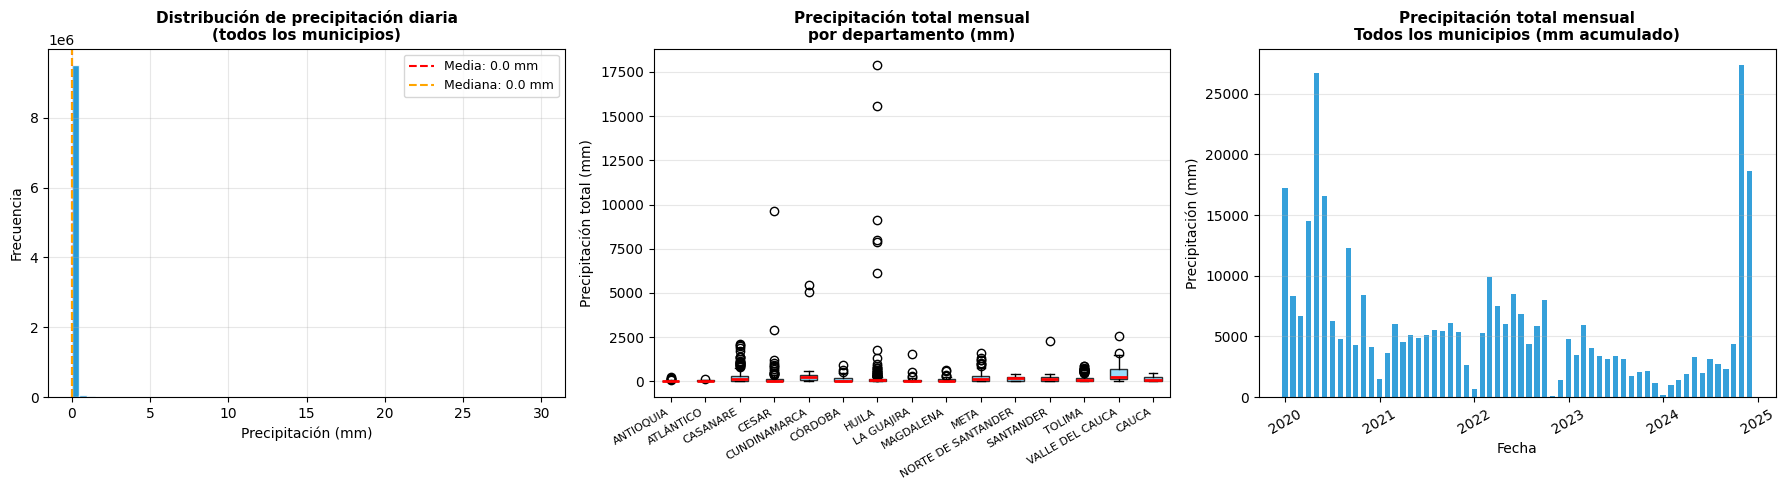

In [ ]:
# ============================================================
# CELDA 13 [v2.0] — Visualización exploratoria de precipitación
# Corrección: detecta automáticamente los nombres de columna
# de año y mes (compatible con carga desde parquet: 'Anio'/'Mes'
# y con descarga directa: 'Año'/'Mes')
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Detectar nombre real de la columna de año ────────────────
col_anio = None
for candidato in ['Año', 'Anio', 'anio', 'año', 'YEAR', 'year']:
    if candidato in df_precipitacion.columns:
        col_anio = candidato
        break

col_mes = None
for candidato in ['Mes', 'mes', 'MES', 'MONTH', 'month']:
    if candidato in df_precipitacion.columns:
        col_mes = candidato
        break

print(f"Columnas detectadas → año: '{col_anio}' | mes: '{col_mes}'")
print(f"Columnas disponibles: {df_precipitacion.columns.tolist()}")

# ── 1. Histograma de precipitación diaria ────────────────────
val = df_precipitacion["valorobservado"].dropna()
axes[0].hist(val, bins=60, color="#0288D1", alpha=0.85, edgecolor="white")
axes[0].set_title("Distribución de precipitación diaria\n(todos los municipios)",
                  fontsize=11, fontweight="bold")
axes[0].set_xlabel("Precipitación (mm)")
axes[0].set_ylabel("Frecuencia")
axes[0].axvline(val.mean(),   color="red",    linestyle="--", linewidth=1.5,
                label=f"Media: {val.mean():.1f} mm")
axes[0].axvline(val.median(), color="orange", linestyle="--", linewidth=1.5,
                label=f"Mediana: {val.median():.1f} mm")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── 2. Boxplot precipitación total mensual por departamento ──
if "departamento" in df_precipitacion.columns and "precipitacion_total" in df_precipitacion_agr_sd.columns:
    deptos    = df_precipitacion_agr_sd["departamento"].unique()
    datos_box = [
        df_precipitacion_agr_sd[
            df_precipitacion_agr_sd["departamento"] == d
        ]["precipitacion_total"].dropna().values
        for d in deptos
    ]
    bp = axes[1].boxplot(datos_box, labels=deptos, patch_artist=True,
                         medianprops={"color": "red", "linewidth": 2})
    for patch in bp["boxes"]:
        patch.set_facecolor("#81D4FA")
        patch.set_alpha(0.8)
    axes[1].set_xticklabels(deptos, rotation=30, ha="right", fontsize=8)
else:
    axes[1].text(0.5, 0.5, "Sin datos\nagregados", ha="center",
                 va="center", transform=axes[1].transAxes)
axes[1].set_title("Precipitación total mensual\npor departamento (mm)",
                  fontsize=11, fontweight="bold")
axes[1].set_ylabel("Precipitación total (mm)")
axes[1].grid(True, alpha=0.3, axis="y")

# ── 3. Serie temporal mensual — usa col_anio y col_mes ───────
if col_anio and col_mes:
    df_serie = (
        df_precipitacion
        .groupby([col_anio, col_mes])["valorobservado"]
        .sum()
        .reset_index()
    )
    df_serie["fecha"] = pd.to_datetime(
        df_serie[col_anio].astype(str) + "-" +
        df_serie[col_mes].astype(str).str.zfill(2) + "-01"
    )
    df_serie = df_serie.sort_values("fecha")
    axes[2].bar(df_serie["fecha"], df_serie["valorobservado"],
                color="#0288D1", alpha=0.8, width=20)
    axes[2].tick_params(axis="x", rotation=30)
    axes[2].grid(True, alpha=0.3, axis="y")
elif "Periodo" in df_precipitacion.columns and "mes_periodo" in df_precipitacion.columns:
    # Fallback: reconstruir fecha desde Periodo + mes_periodo
    df_serie = (
        df_precipitacion
        .groupby(["Periodo", "mes_periodo"])["valorobservado"]
        .sum()
        .reset_index()
    )
    df_serie["_anio"]     = df_serie["Periodo"].str[:4].astype(int)
    df_serie["_semestre"] = df_serie["Periodo"].str[4]
    df_serie["_offset"]   = df_serie["_semestre"].map({"A": 0, "B": 6}).fillna(0).astype(int)
    df_serie["_mes_real"] = df_serie["mes_periodo"].astype(int) + df_serie["_offset"]
    df_serie["fecha"] = pd.to_datetime(
        df_serie["_anio"].astype(str) + "-" +
        df_serie["_mes_real"].astype(str).str.zfill(2) + "-01"
    )
    df_serie = df_serie.sort_values("fecha")
    axes[2].bar(df_serie["fecha"], df_serie["valorobservado"],
                color="#0288D1", alpha=0.8, width=20)
    axes[2].tick_params(axis="x", rotation=30)
    axes[2].grid(True, alpha=0.3, axis="y")
    print("Nota: fecha reconstruida desde Periodo + mes_periodo (columnas Año/Mes no disponibles)")
else:
    axes[2].text(0.5, 0.5, "Sin columnas\nde fecha", ha="center",
                 va="center", transform=axes[2].transAxes)

axes[2].set_title("Precipitación total mensual\nTodos los municipios (mm acumulado)",
                  fontsize=11, fontweight="bold")
axes[2].set_ylabel("Precipitación (mm)")
axes[2].set_xlabel("Fecha")

plt.tight_layout()
plt.show()

---
# ☀️ PARTE B — RADIACIÓN SOLAR (NASA POWER API)

---
## 🔧 CELDA 14 — Funciones específicas para NASA POWER

La API NASA POWER devuelve datos **mensuales** directamente,  
por lo que no requiere agregación diaria como las fuentes IDEAM.  
Se parsea el JSON anidado `properties → parameter → PARAM → {YYYYMM: valor}`.

In [ ]:
# ============================================================
# FUNCIONES NASA POWER — Descarga y parseo de radiación solar
# ============================================================

def descargar_nasa_power(lat, lon, anio_ini, anio_fin,
                         parametros=NASA_PARAMS,
                         timeout=TIMEOUT_NASA):
    """
    Descarga datos mensuales de la API NASA POWER para un punto (lat, lon).

    Parámetros principales (community=AG, uso agrícola):
      ALLSKY_SFC_SW_DWN : Radiación solar total en superficie (MJ/m²/día)
      CLRSKY_SFC_SW_DWN : Radiación bajo cielo despejado (MJ/m²/día)

    Retorna un DataFrame con columnas:
      [param, year, month, value, Semestre, Periodo, mes_periodo]
    o DataFrame vacío si hay error / sin datos.
    """
    params = {
        "parameters" : parametros,
        "community"  : "AG",
        "longitude"  : round(lon, 4),
        "latitude"   : round(lat, 4),
        "format"     : "JSON",
        "start"      : anio_ini,
        "end"        : anio_fin,
    }
    try:
        r = requests.get(URL_NASA_POWER, params=params, timeout=timeout)
        r.raise_for_status()
        data = r.json()
    except Exception as e:
        print(f"    ⚠️  Error NASA POWER: {e}")
        return pd.DataFrame()

    # Parsear el JSON anidado
    try:
        param_dict = data["properties"]["parameter"]
    except (KeyError, TypeError):
        print(f"    ⚠️  Estructura inesperada en respuesta NASA POWER")
        return pd.DataFrame()

    rows = []
    for param_name, valores in param_dict.items():
        for yyyymm, val in valores.items():
            if val == NASA_FILL_VALUE:   # -999 = dato faltante
                continue
            year  = int(str(yyyymm)[:4])
            month = int(str(yyyymm)[4:])
            rows.append({
                "parametro"  : param_name,
                "year"       : year,
                "month"      : month,
                "valor"      : float(val),
            })

    if not rows:
        return pd.DataFrame()

    df = pd.DataFrame(rows)

    # Variables de calendario (mismo esquema que MOD-03)
    df["Semestre"]   = df["month"].map(
        lambda x: "A" if x <= 6 else "B"
    )
    df["Periodo"]    = df["year"].astype(str) + df["Semestre"]
    df["mes_periodo"] = ((df["month"] - 1) % 6) + 1

    return df


def parsear_radiacion_a_long(df_nasa, depto, mpio, lat, lon):
    """
    Agrega identificadores territoriales y pivotea por parámetro
    para obtener una fila por (year, month) con columnas de cada parámetro.
    """
    df = df_nasa.copy()
    df["departamento"] = depto
    df["municipio"]    = mpio
    df["latitud_nasa"] = lat
    df["longitud_nasa"] = lon

    # Pivotar para tener una columna por parámetro
    df_pivot = df.pivot_table(
        index=["departamento","municipio","latitud_nasa","longitud_nasa",
               "year","month","Semestre","Periodo","mes_periodo"],
        columns="parametro",
        values="valor",
        aggfunc="first"
    ).reset_index()
    df_pivot.columns.name = None

    # Renombrar a nombres más legibles
    rename_map = {
        "ALLSKY_SFC_SW_DWN" : "radiacion_allsky",
        "CLRSKY_SFC_SW_DWN" : "radiacion_clearsky",
    }
    df_pivot = df_pivot.rename(columns=rename_map)

    return df_pivot


print("✅ Funciones NASA POWER cargadas")

✅ Funciones NASA POWER cargadas


---
## 🛰️ CELDA 15 — Descarga de radiación solar desde NASA POWER

> Esta celda realiza una petición HTTP por cada municipio.  
> La API NASA POWER tiene un límite de ~30 peticiones/minuto, por lo que  
> se incluye una pausa de 2 segundos entre peticiones.

In [ ]:
# ============================================================
# LIBERAR PRECIPITACION ANTES DE DESCARGAR RADIACION
# En este punto df_precipitacion ya fue agregado y guardado.
# Lo liberamos para dar espacio a la descarga NASA POWER.
# ============================================================
print('Liberando df_precipitacion antes de descarga NASA...')
del df_precipitacion
limpiar_ram(etapa='pre-NASA')

# ============================================================
# DESCARGA NASA POWER — Radiación solar mensual (2020-2024)
# ============================================================

print("🛰️  Iniciando descarga de radiación solar — NASA POWER")
print(f"   URL    : {URL_NASA_POWER}")
print(f"   Params : {NASA_PARAMS}")
print(f"   Rango  : {ANIO_INI_NASA} → {ANIO_FIN_NASA}")
print(f"   Municipios: {len(filtros)}")
print("=" * 58)

dfs_rad      = []
sin_coords   = []
sin_datos    = []
t_inicio     = time.time()

for i, (depto, mpio) in enumerate(filtros, start=1):
    print(f"\n[{i}/{len(filtros)}] {depto} — {mpio}")

    # Obtener coordenadas del catálogo de estaciones
    key = f"{depto}|{mpio}"
    match_coord = df_coordenadas[df_coordenadas["key"] == key]

    if len(match_coord) == 0:
        print(f"    ⚠️  Sin coordenadas disponibles — municipio omitido")
        sin_coords.append((depto, mpio))
        continue

    lat = float(match_coord["lat"].values[0])
    lon = float(match_coord["lon"].values[0])
    print(f"    Coordenadas: lat={lat:.3f}, lon={lon:.3f}")

    # Descargar datos NASA POWER
    df_nasa = descargar_nasa_power(
        lat, lon,
        anio_ini = ANIO_INI_NASA,
        anio_fin = ANIO_FIN_NASA,
    )

    if df_nasa.empty:
        print(f"    ⚠️  Sin datos NASA POWER")
        sin_datos.append((depto, mpio))
        continue

    # Parsear a formato largo con identificadores
    df_rad_i = parsear_radiacion_a_long(df_nasa, depto, mpio, lat, lon)
    dfs_rad.append(df_rad_i)
    print(f"    ✅ {len(df_rad_i)} meses descargados")

    # Pausa cortés con la API NASA POWER
    time.sleep(2)

# ── Consolidar ──────────────────────────────────────────────
df_radiacion_raw = (
    pd.concat(dfs_rad, ignore_index=True) if dfs_rad else pd.DataFrame()
)

t_total = time.time() - t_inicio
print(f"\n{'='*58}")
print(f"  ✅ Descarga NASA POWER completada en {t_total/60:.1f} min")
print(f"  Total filas (meses × municipios): {len(df_radiacion_raw):,}")
print(f"  Municipios con datos  : {len(filtros)-len(sin_coords)-len(sin_datos)}/{len(filtros)}")
if sin_coords:
    print(f"  Sin coordenadas      : {sin_coords}")
if sin_datos:
    print(f"  Sin datos NASA POWER : {sin_datos}")
print(f"{'='*58}")

Liberando df_precipitacion antes de descarga NASA...
  🔴 RAM usada [pre-NASA]: 5,738 MB
🛰️  Iniciando descarga de radiación solar — NASA POWER
   URL    : https://power.larc.nasa.gov/api/temporal/monthly/point
   Params : ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN
   Rango  : 2020 → 2024
   Municipios: 131

[1/131] ANTIOQUIA — PUERTO BERRÍO
    Coordenadas: lat=6.496, lon=-74.410
    ✅ 65 meses descargados

[2/131] ARAUCA — FORTUL
    ⚠️  Sin coordenadas disponibles — municipio omitido

[3/131] ATLÁNTICO — PONEDERA
    ⚠️  Sin coordenadas disponibles — municipio omitido

[4/131] ATLÁNTICO — REPELÓN
    ⚠️  Sin coordenadas disponibles — municipio omitido

[5/131] ATLÁNTICO — SUAN
    ⚠️  Sin coordenadas disponibles — municipio omitido

[6/131] BOLÍVAR — ACHÍ
    ⚠️  Sin coordenadas disponibles — municipio omitido

[7/131] BOLÍVAR — ARENAL
    ⚠️  Sin coordenadas disponibles — municipio omitido

[8/131] BOLÍVAR — CLEMENCIA
    ⚠️  Sin coordenadas disponibles — municipio omitido

[9/131] BOLÍVAR

---
## 💾 CELDA 16 — Guardar descarga raw de radiación en `data/raw/`

In [ ]:
# ============================================================
# GUARDAR RAW RADIACIÓN — data/raw/04b_raw_Radiacion_NASA.parquet
# ============================================================

if not df_radiacion_raw.empty:
    df_radiacion_raw.to_parquet(ARCHIVO_RAD_RAW, index=False)
    size_mb = os.path.getsize(ARCHIVO_RAD_RAW) / 1_048_576
    print(f"✅ Guardado: 04b_raw_Radiacion_NASA.parquet")
    print(f"   Ruta  : {ARCHIVO_RAD_RAW}")
    print(f"   Shape : {df_radiacion_raw.shape[0]:,} × {df_radiacion_raw.shape[1]}")
    print(f"   Tamaño: {size_mb:.3f} MB")
    print(f"\n📋 Columnas:")
    print(df_radiacion_raw.columns.tolist())
    print()
    display(df_radiacion_raw.head(6))
else:
    print("❌ No hay datos de radiación. Revisa conectividad y coordenadas.")

✅ Guardado: 04b_raw_Radiacion_NASA.parquet
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw/04b_raw_Radiacion_NASA.parquet
   Shape : 6,825 × 11
   Tamaño: 0.031 MB

📋 Columnas:
['departamento', 'municipio', 'latitud_nasa', 'longitud_nasa', 'year', 'month', 'Semestre', 'Periodo', 'mes_periodo', 'radiacion_allsky', 'radiacion_clearsky']



,departamento,municipio,latitud_nasa,longitud_nasa,year,month,Semestre,Periodo,mes_periodo,radiacion_allsky,radiacion_clearsky
0,ANTIOQUIA,PUERTO BERRÍO,6.496181,-74.410083,2020,1,A,2020A,1,19.71,23.02
1,ANTIOQUIA,PUERTO BERRÍO,6.496181,-74.410083,2020,2,A,2020A,2,20.49,23.98
2,ANTIOQUIA,PUERTO BERRÍO,6.496181,-74.410083,2020,3,A,2020A,3,18.08,23.15
3,ANTIOQUIA,PUERTO BERRÍO,6.496181,-74.410083,2020,4,A,2020A,4,17.93,24.58
4,ANTIOQUIA,PUERTO BERRÍO,6.496181,-74.410083,2020,5,A,2020A,5,19.02,24.93
5,ANTIOQUIA,PUERTO BERRÍO,6.496181,-74.410083,2020,6,A,2020A,6,18.67,24.46


---
## 📐 CELDA 17 — Agregación de radiación solar por mes_periodo y pivoteo wide

La API NASA POWER devuelve datos mensuales directamente, por lo que **no requiere  
agregación diaria**. La única transformación necesaria es el pivoteo a formato wide.

In [ ]:
# ============================================================
# AGREGACIÓN Y PIVOTEO WIDE — Radiación solar
# ============================================================

df_radiacion = df_radiacion_raw.copy()

# Detectar columnas de radiación disponibles
COLS_RAD = [c for c in ["radiacion_allsky", "radiacion_clearsky"]
            if c in df_radiacion.columns]

print(f"📋 Columnas de radiación disponibles: {COLS_RAD}")

# ── Control de calidad: eliminar fill values residuales ──────
for col in COLS_RAD:
    df_radiacion[col] = pd.to_numeric(df_radiacion[col], errors="coerce")
    # Marcar fill values como NaN
    df_radiacion.loc[df_radiacion[col] == NASA_FILL_VALUE, col] = np.nan

# ── Guardar serie larga radiación ────────────────────────────
# Radiación NASA POWER es mensual: ~200 mun × 60 meses = 12,000 filas → Excel seguro
# Se aplica guarda condicional por robustez ante cambios futuros de escala.
n_filas_rad = df_radiacion.shape[0]
print(f"📊 Serie radiación: {n_filas_rad:,} filas × {df_radiacion.shape[1]} columnas")
if n_filas_rad <= 1_048_576:
    guardar_excel(df_radiacion, ARCHIVO_RAD_LONG, "23_DF_Radiacion_Long.xlsx")
else:
    # Fallback Parquet si la escala crece inesperadamente
    archivo_rad_long_parquet = ARCHIVO_RAD_LONG.replace(".xlsx", ".parquet")
    df_radiacion.to_parquet(archivo_rad_long_parquet, index=False)
    df_radiacion.head(50_000).to_excel(ARCHIVO_RAD_LONG, index=False, engine="openpyxl")
    print(f"⚠️  Radiación supera 1M filas — guardado en Parquet + muestra Excel")
    print(f"   Parquet: {archivo_rad_long_parquet}")

# ── Verificar distribución de mes_periodo ────────────────────
print("📊 Distribución de mes_periodo en radiación:")
print(df_radiacion["mes_periodo"].value_counts().sort_index().to_string())

# ── Pivoteo wide ─────────────────────────────────────────────
print("\n🔄 Pivoteando radiación a formato wide...")

df_radiacion_wide = pivotar_wide(
    df_radiacion,
    cols_valores = COLS_RAD
)

reporte_df(df_radiacion_wide, "df_radiacion_wide (m1..m6)")

print("📋 Columnas wide generadas:")
cols_id = ["Periodo","departamento","municipio"]
for col in [c for c in df_radiacion_wide.columns if c not in cols_id]:
    print(f"   {col}")

print()
display(df_radiacion_wide.head(4))

📋 Columnas de radiación disponibles: ['radiacion_allsky', 'radiacion_clearsky']
📊 Serie radiación: 6,825 filas × 11 columnas
OK 23_DF_Radiacion_Long.xlsx -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/23_DF_Radiacion_Long.xlsx
   Shape : 6,825 x 11

📊 Distribución de mes_periodo en radiación:
mes_periodo
1    1575
2    1050
3    1050
4    1050
5    1050
6    1050

🔄 Pivoteando radiación a formato wide...

  DataFrame -- df_radiacion_wide (m1..m6)
  Filas    : 1,050
  Columnas : 15
  Nulos    : Sin valores nulos

📋 Columnas wide generadas:
   radiacion_allsky_m1
   radiacion_allsky_m2
   radiacion_allsky_m3
   radiacion_allsky_m4
   radiacion_allsky_m5
   radiacion_allsky_m6
   radiacion_clearsky_m1
   radiacion_clearsky_m2
   radiacion_clearsky_m3
   radiacion_clearsky_m4
   radiacion_clearsky_m5
   radiacion_clearsky_m6



,Periodo,departamento,municipio,radiacion_allsky_m1,radiacion_allsky_m2,radiacion_allsky_m3,radiacion_allsky_m4,radiacion_allsky_m5,radiacion_allsky_m6,radiacion_clearsky_m1,radiacion_clearsky_m2,radiacion_clearsky_m3,radiacion_clearsky_m4,radiacion_clearsky_m5,radiacion_clearsky_m6
0,2020A,ANTIOQUIA,PUERTO BERRÍO,19.71,20.49,18.08,17.93,19.02,18.67,23.02,23.98,23.15,24.58,24.93,24.46
1,2020A,CASANARE,AGUAZUL,18.36,20.28,17.37,15.76,14.42,15.15,24.51,25.74,25.08,25.40,25.51,25.00
2,2020A,CASANARE,NUNCHÍA,18.36,20.28,17.37,15.76,14.42,15.15,24.51,25.74,25.08,25.40,25.51,25.00
3,2020A,CASANARE,PAZ DE ARIPORO,20.81,22.19,20.53,17.55,17.03,16.41,23.70,24.97,24.52,24.71,24.74,24.04


---
## 💾 CELDA 18 — Guardar formato wide de radiación en `data/processed/`

In [ ]:
# ============================================================
# GUARDAR FORMATO WIDE RADIACIÓN
# Destino: data/processed/24_DF_Radiacion_Wide.xlsx
# ============================================================

guardar_excel(
    df_radiacion_wide,
    ARCHIVO_RAD_WIDE,
    nombre_log="24_DF_Radiacion_Wide.xlsx"
)

OK 24_DF_Radiacion_Wide.xlsx -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/24_DF_Radiacion_Wide.xlsx
   Shape : 1,050 x 15



---
## 📊 CELDA 19 — Visualización comparativa: precipitación vs radiación solar

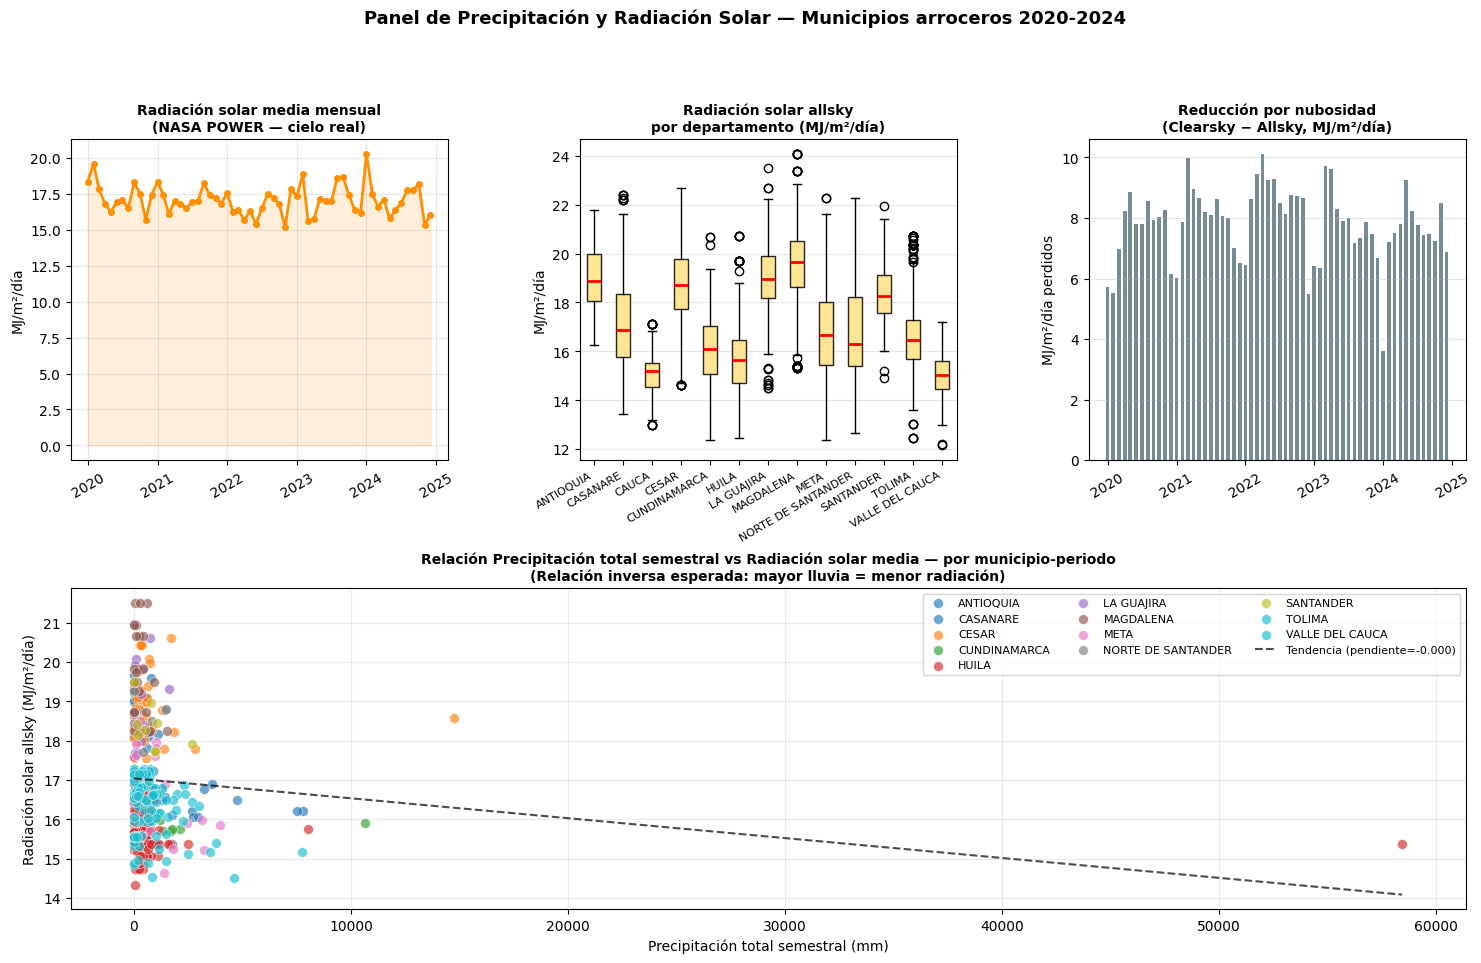

In [ ]:
# ============================================================
# VISUALIZACIÓN — Precipitación vs Radiación Solar
# Relación inversa esperada: más lluvia = menos radiación
# ============================================================

fig = plt.figure(figsize=(18, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

# ── Utilidad interna: reconstruir fecha real desde Periodo + mes_periodo ─
# Periodo = 'YYYYS' (ej. '2022A'), mes_periodo = 1..6
# mes real = mes_periodo + (0 si semestre A, 6 si semestre B)
def _fecha_desde_periodo(df):
    """Reconstruye mes calendario real (1-12) a partir de Periodo y mes_periodo."""
    df = df.copy()
    df["_anio"]     = df["Periodo"].str[:4].astype(int)
    df["_semestre"] = df["Periodo"].str[4]
    df["_offset"]   = df["_semestre"].map({"A": 0, "B": 6})
    df["_mes_real"] = df["mes_periodo"].astype(int) + df["_offset"]
    df["fecha"] = pd.to_datetime(
        df["_anio"].astype(str) + "-" +
        df["_mes_real"].astype(str).str.zfill(2) + "-01",
        format="%Y-%m-%d"
    )
    return df.drop(columns=["_anio","_semestre","_offset","_mes_real"])

# ── Gráfica 1: Radiación allsky mensual (serie de tiempo) ────
ax1 = fig.add_subplot(gs[0, 0])
if "radiacion_allsky" in df_radiacion.columns:
    df_rad_m = (
        df_radiacion
        .groupby(["Periodo", "mes_periodo"])["radiacion_allsky"]
        .mean().reset_index()
    )
    df_rad_m = _fecha_desde_periodo(df_rad_m).sort_values("fecha")
    ax1.plot(df_rad_m["fecha"], df_rad_m["radiacion_allsky"],
             color="#FF8F00", linewidth=2, marker="o", markersize=4)
    ax1.fill_between(df_rad_m["fecha"], df_rad_m["radiacion_allsky"],
                     alpha=0.15, color="#FF8F00")
ax1.set_title("Radiación solar media mensual\n(NASA POWER — cielo real)",
              fontsize=10, fontweight="bold")
ax1.set_ylabel("MJ/m²/día")
ax1.tick_params(axis="x", rotation=30)
ax1.grid(True, alpha=0.3)

# ── Gráfica 2: Boxplot radiación por departamento ────────────
ax2 = fig.add_subplot(gs[0, 1])
if "radiacion_allsky" in df_radiacion.columns:
    deptos = df_radiacion["departamento"].unique()
    datos_box = [
        df_radiacion[df_radiacion["departamento"]==d]["radiacion_allsky"].dropna().values
        for d in deptos
    ]
    bp = ax2.boxplot(datos_box, labels=deptos, patch_artist=True,
                     medianprops={"color": "red", "linewidth": 2})
    for patch in bp["boxes"]:
        patch.set_facecolor("#FFE082")
        patch.set_alpha(0.85)
ax2.set_title("Radiación solar allsky\npor departamento (MJ/m²/día)",
              fontsize=10, fontweight="bold")
ax2.set_ylabel("MJ/m²/día")
ax2.set_xticklabels(deptos, rotation=30, ha="right", fontsize=8)
ax2.grid(True, alpha=0.3, axis="y")

# ── Gráfica 3: Allsky vs Clearsky (diferencia = efecto nubes) ─
ax3 = fig.add_subplot(gs[0, 2])
if "radiacion_allsky" in df_radiacion.columns and "radiacion_clearsky" in df_radiacion.columns:
    df_rad_comp = (
        df_radiacion
        .groupby(["Periodo", "mes_periodo"])[["radiacion_allsky","radiacion_clearsky"]]
        .mean().reset_index()
    )
    df_rad_comp = _fecha_desde_periodo(df_rad_comp).sort_values("fecha")
    df_rad_comp["efecto_nubes"] = (
        df_rad_comp["radiacion_clearsky"] - df_rad_comp["radiacion_allsky"]
    )
    ax3.bar(df_rad_comp["fecha"], df_rad_comp["efecto_nubes"],
            color="#546E7A", alpha=0.8, width=20)
    ax3.set_title("Reducción por nubosidad\n(Clearsky − Allsky, MJ/m²/día)",
                  fontsize=10, fontweight="bold")
    ax3.set_ylabel("MJ/m²/día perdidos")
    ax3.tick_params(axis="x", rotation=30)
    ax3.grid(True, alpha=0.3, axis="y")

# ── Gráfica 4: Precipitación mensual vs Radiación (scatter) ──
ax4 = fig.add_subplot(gs[1, :])
# Cruzar precipitación y radiación por Periodo-Depto-Municipio
df_prec_sum = (
    df_precipitacion_agr_sd
    .groupby(["Periodo","departamento","municipio"])["precipitacion_total"]
    .sum().reset_index()
)
if "radiacion_allsky" in df_radiacion.columns:
    df_rad_mean = (
        df_radiacion
        .groupby(["Periodo","departamento","municipio"])["radiacion_allsky"]
        .mean().reset_index()
    )
    df_scatter = df_prec_sum.merge(
        df_rad_mean,
        on=["Periodo","departamento","municipio"],
        how="inner"
    )

    deptos_unicos = df_scatter["departamento"].unique()
    colores_dep   = plt.cm.tab10(np.linspace(0, 1, len(deptos_unicos)))
    for j, (dep, color) in enumerate(zip(deptos_unicos, colores_dep)):
        sub = df_scatter[df_scatter["departamento"]==dep]
        ax4.scatter(
            sub["precipitacion_total"],
            sub["radiacion_allsky"],
            s=50, alpha=0.65, color=color, label=dep, edgecolors="white", linewidths=0.5
        )

    # Línea de tendencia general
    x_vals = df_scatter["precipitacion_total"].dropna()
    y_vals = df_scatter["radiacion_allsky"].dropna()
    if len(x_vals) > 5:
        z = np.polyfit(x_vals, y_vals, 1)
        p = np.poly1d(z)
        x_range = np.linspace(x_vals.min(), x_vals.max(), 100)
        ax4.plot(x_range, p(x_range), "k--", linewidth=1.5,
                 alpha=0.7, label=f"Tendencia (pendiente={z[0]:.3f})")

ax4.set_title(
    "Relación Precipitación total semestral vs Radiación solar media — por municipio-periodo\n"
    "(Relación inversa esperada: mayor lluvia = menor radiación)",
    fontsize=10, fontweight="bold"
)
ax4.set_xlabel("Precipitación total semestral (mm)")
ax4.set_ylabel("Radiación solar allsky (MJ/m²/día)")
ax4.legend(loc="upper right", fontsize=8, ncol=3)
ax4.grid(True, alpha=0.25)

plt.suptitle(
    "Panel de Precipitación y Radiación Solar — Municipios arroceros 2020-2024",
    fontsize=13, fontweight="bold", y=1.01
)
plt.show()

---
## ✅ CELDA 20 — Resumen de ejecución del módulo

In [ ]:
# ============================================================
# CELDA 20 [v3.0] — Resumen de ejecución del módulo
# Corrección: lee conteos directamente desde los archivos
# guardados en disco. No depende de ningún DataFrame en memoria
# (df_precipitacion y df_precipitacion_raw pueden haber sido
# liberados con del en celdas anteriores para ahorrar RAM).
# ============================================================

import pyarrow.parquet as pq

def contar_filas_parquet(ruta):
    """Lee solo los metadatos del parquet (O(1), sin cargar datos)."""
    try:
        return f"{pq.read_metadata(ruta).num_rows:,}"
    except Exception:
        try:
            return f"{os.path.getsize(ruta)/1_048_576:.1f} MB"
        except Exception:
            return "archivo no encontrado"

def contar_filas_excel(ruta):
    """Lee solo la primera columna para contar filas (sin cargar todo)."""
    try:
        return f"{len(pd.read_excel(ruta, usecols=[0], engine='openpyxl')):,}"
    except Exception:
        return "archivo no encontrado"

def shape_df(nombre_df, df_dict):
    """Retorna shape si el DataFrame sigue en memoria, si no usa disco."""
    df = df_dict.get(nombre_df)
    if df is not None and not df.empty:
        return f"{df.shape[0]:,} filas × {df.shape[1]} cols"
    return "liberado de memoria (ver archivo en disco)"

# DataFrames que pueden o no estar en memoria
dfs_vivos = {}
for nombre in ['df_precipitacion', 'df_precipitacion_agr',
               'df_precipitacion_agr_sd', 'df_precipitacion_wide',
               'df_radiacion', 'df_radiacion_wide']:
    try:
        df_vivo = eval(nombre)
        dfs_vivos[nombre] = df_vivo
    except NameError:
        dfs_vivos[nombre] = None

print("=" * 65)
print("  ✅ MOD-04 — Precipitación + Radiación Solar  COMPLETADO")
print("=" * 65)

print("\n🌧️  PARTE A — Precipitación (datos.gov.co · IDEAM):")
salidas_a = [
    ("data/raw/",       "04a_raw_Precipitacion.parquet",   ARCHIVO_PREC_RAW,         contar_filas_parquet(ARCHIVO_PREC_RAW)),
    ("data/processed/", "19_DF_Precipitacion_Long.parquet", ARCHIVO_PREC_LONG_PARQUET, contar_filas_parquet(ARCHIVO_PREC_LONG_PARQUET)),
    ("data/processed/", "20_DF_Precipitacion_Agr.parquet",  ARCHIVO_PREC_AGR_PARQUET,  contar_filas_parquet(ARCHIVO_PREC_AGR_PARQUET)),
    ("data/processed/", "21_DF_Precipitacion_Agr_SD.xlsx",  ARCHIVO_PREC_AGR_SD,       contar_filas_excel(ARCHIVO_PREC_AGR_SD)),
    ("data/processed/", "22_DF_Precipitacion_Wide.xlsx",    ARCHIVO_PREC_WIDE,         contar_filas_excel(ARCHIVO_PREC_WIDE)),
]
for carpeta, archivo, ruta, conteo in salidas_a:
    existe = "✅" if os.path.exists(ruta) else "❌"
    print(f"   {existe} {carpeta}{archivo}")
    print(f"      {conteo}")

print("\n☀️  PARTE B — Radiación Solar (NASA POWER):")
salidas_b = [
    ("data/raw/",       "04b_raw_Radiacion_NASA.parquet", ARCHIVO_RAD_RAW,  contar_filas_parquet(ARCHIVO_RAD_RAW)),
    ("data/processed/", "23_DF_Radiacion_Long.xlsx",       ARCHIVO_RAD_LONG, contar_filas_excel(ARCHIVO_RAD_LONG)),
    ("data/processed/", "24_DF_Radiacion_Wide.xlsx",       ARCHIVO_RAD_WIDE, contar_filas_excel(ARCHIVO_RAD_WIDE)),
]
for carpeta, archivo, ruta, conteo in salidas_b:
    existe = "✅" if os.path.exists(ruta) else "❌"
    print(f"   {existe} {carpeta}{archivo}")
    print(f"      {conteo}")

print("\n📊 DataFrames en memoria al finalizar:")
for nombre, df in dfs_vivos.items():
    if df is not None:
        print(f"   ✅ {nombre:<35} → {df.shape[0]:,} filas × {df.shape[1]} cols")
    else:
        print(f"   🗑️  {nombre:<35} → liberado (del) para ahorrar RAM")

print("\n➡️  Siguiente módulo : MOD-05 — Humedad Relativa")
print("    Entradas esperadas:")
print("      22_DF_Precipitacion_Wide.xlsx  (este módulo — Parte A)")
print("      24_DF_Radiacion_Wide.xlsx      (este módulo — Parte B)")
print("=" * 65)

  ✅ MOD-04 — Precipitación + Radiación Solar  COMPLETADO

🌧️  PARTE A — Precipitación (datos.gov.co · IDEAM):
   ✅ data/raw/04a_raw_Precipitacion.parquet
      9,618,437
   ✅ data/processed/19_DF_Precipitacion_Long.parquet
      9,618,437
   ✅ data/processed/20_DF_Precipitacion_Agr.parquet
      45,314
   ✅ data/processed/21_DF_Precipitacion_Agr_SD.xlsx
      1,845
   ✅ data/processed/22_DF_Precipitacion_Wide.xlsx
      394

☀️  PARTE B — Radiación Solar (NASA POWER):
   ✅ data/raw/04b_raw_Radiacion_NASA.parquet
      6,825
   ✅ data/processed/23_DF_Radiacion_Long.xlsx
      6,825
   ✅ data/processed/24_DF_Radiacion_Wide.xlsx
      1,050

📊 DataFrames en memoria al finalizar:
   🗑️  df_precipitacion                    → liberado (del) para ahorrar RAM
   🗑️  df_precipitacion_agr                → liberado (del) para ahorrar RAM
   ✅ df_precipitacion_agr_sd             → 1,845 filas × 10 cols
   ✅ df_precipitacion_wide               → 394 filas × 33 cols
   ✅ df_radiacion                

In [ ]:
# ============================================================
# RESUMEN FINAL — MOD-04 completado
# ============================================================

print("=" * 65)
print("  ✅ MOD-04 — Precipitación + Radiación Solar  COMPLETADO")
print("=" * 65)

print("\n🌧️  PARTE A — Precipitación (datos.gov.co · IDEAM):")
salidas_a = [
    ("data/raw/",       "04a_raw_Precipitacion.parquet",
     f"Descarga original — {df_precipitacion_raw.shape[0]:,} registros"),
    ("data/processed/", "19_DF_Precipitacion_Long.xlsx",
     f"Serie larga con calendario — {df_precipitacion.shape[0]:,} filas"),
    ("data/processed/", "20_DF_Precipitacion_Agr.xlsx",
     f"Métricas diarias — {df_precipitacion_agr.shape[0]:,} filas"),
    ("data/processed/", "21_DF_Precipitacion_Agr_SD.xlsx",
     f"Métricas mes semestral — {df_precipitacion_agr_sd.shape[0]:,} filas"),
    ("data/processed/", "22_DF_Precipitacion_Wide.xlsx",
     f"Formato wide m1..m6 — {df_precipitacion_wide.shape[0]:,} filas × {df_precipitacion_wide.shape[1]} cols"),
]
for carpeta, archivo, desc in salidas_a:
    print(f"   📄 {carpeta}{archivo}")
    print(f"      {desc}")

print("\n☀️  PARTE B — Radiación Solar (NASA POWER):")
salidas_b = [
    ("data/raw/",       "04b_raw_Radiacion_NASA.parquet",
     f"Descarga original — {df_radiacion_raw.shape[0]:,} filas"),
    ("data/processed/", "23_DF_Radiacion_Long.xlsx",
     f"Serie mensual con calendario — {df_radiacion.shape[0]:,} filas"),
    ("data/processed/", "24_DF_Radiacion_Wide.xlsx",
     f"Formato wide m1..m6 — {df_radiacion_wide.shape[0]:,} filas × {df_radiacion_wide.shape[1]} cols"),
]
for carpeta, archivo, desc in salidas_b:
    print(f"   📄 {carpeta}{archivo}")
    print(f"      {desc}")

print("\n📊 DataFrames disponibles para módulos siguientes:")
print("   Precipitación:")
print(f"   df_precipitacion         → serie larga")
print(f"   df_precipitacion_agr     → métricas diarias")
print(f"   df_precipitacion_agr_sd  → métricas por mes semestral")
print(f"   df_precipitacion_wide    → LISTO para MOD-05 ✅")
print("   Radiación:")
print(f"   df_radiacion             → serie mensual larga")
print(f"   df_radiacion_wide        → LISTO para MOD-05 ✅")

print("\n🗺️  Cobertura:")
print(f"   Precipitación — periodos: {sorted(df_precipitacion_wide['Periodo'].unique()) if not df_precipitacion_wide.empty else []}")
print(f"   Radiación     — periodos: {sorted(df_radiacion_wide['Periodo'].unique())}")

print("\n➡️  Siguiente módulo : MOD-06 — Consolidación del Dataset Maestro")
print("    Entradas esperadas:")
print("      11_DF_Produccion_Agricola.xlsx  (MOD-01)")
print("      18_DF_Temperatura_Wide.xlsx     (MOD-04)")
print("      22_DF_Precipitacion_Wide.xlsx   (MOD-05 — Parte A)")
print("      24_DF_Radiacion_Wide.xlsx       (MOD-05 — Parte B)")
print("=" * 65)

  ✅ MOD-04 — Precipitación + Radiación Solar  COMPLETADO

🌧️  PARTE A — Precipitación (datos.gov.co · IDEAM):


NameError: name 'df_precipitacion_raw' is not defined